<a href="https://colab.research.google.com/github/yuniecorn-dev/esaa_assignment2/blob/main/ESAA_OB_WEEK11_study_1113.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

* 테스트 정확도가 낮을 경우(예 56%) 다른 유형의 모델로 변경하여 비교 테스트를 진행해야 함
* 학습률(learning rate)이나 배치 크기(batch size)처럼 사용자가 직접 지정해야 하는 하이퍼파라미터를 튜닝하며 최적의 성능을 찾아야 함

## LSTM (Long Short-Term Memory) 구조

### 등장 배경
* 기존 RNN은 가중치 업데이트 과정에서 1보다 작은 기울기가 계속 곱해지며 기울기가 사라지는 **기울기 소멸 문제**가 발생함
* 이를 해결하기 위해 은닉층의 각 뉴런에 게이트(Gate)와 메모리 셀(Cell)을 추가한 확장형 RNN 모델임

### LSTM 순전파 (3가지 게이트 + 셀)
과거 정보($h_{t-1}$)와 현재 데이터($x_t$)를 입력받아 정보를 선별하고 전달함

* **망각 게이트(Forget Gate)**
  * 과거 정보를 어느 정도 기억할지 결정함
  * **시그모이드($\sigma$)** 출력(0~1)을 과거 셀 상태에 곱하며, 값이 `1`이면 직전 정보를 유지하고 `0`이면 초기화함
  * 수식 $f_t = \sigma(w_f[h_{t-1}, x_t])$
* **입력 게이트(Input Gate)**
  * 현재 새로운 정보를 얼마나 기억할지 결정함
  * **시그모이드($\sigma$)**(허용 및 차단 결정)와 **$\tanh$**(후보 값 생성)를 결합해 반영량을 산출함
  * 수식 $i_t = \sigma(w_i[h_{t-1}, x_t])$, $\tilde{c}_t = \tanh(w_c[h_{t-1}, x_t])$
* **메모리 셀(Cell State)**
  * 장기 기억을 저장하며 기울기 소멸 문제를 해결함
  * 망각 게이트 결과와 입력 게이트 결과를 **더하기(`+`)** 연산으로 업데이트함
  * 수식 $c_t = f_t \cdot c_{t-1} + i_t \cdot \tilde{c}_t$
* **출력 게이트(Output Gate)**
  * 갱신된 셀 중 무엇을 최종 출력할지 결정함
  * **시그모이드($\sigma$)** 출력과 $\tanh$를 거친 현재 셀 상태를 곱해 다음 은닉 상태($h_t$)를 도출함
  * 수식 $o_t = \sigma(w_o[h_{t-1}, x_t])$, $h_t = o_t \cdot \tanh(c_t)$

### LSTM 역전파
* 최종 오차가 메모리 셀을 통해 모든 노드에 끊김 없이 전파되므로 **중단 없는 기울기(uninterrupted gradient flow)**라고 부름
* 셀 단위로 오차가 전파되더라도 셀 내부적으로는 입력($x_t$) 방향으로도 오차가 정상적으로 전파됨

## 실습 예제

### ① LSTM 셀 구현 (MNIST 손글씨 분류)
* 얀 르쿤 교수가 만든 $28 \times 28$ 픽셀 손글씨 숫자(0~9) 이미지 데이터셋을 사용함 (훈련 6만 개, 검증 및 테스트 1만 개)
* 선형 계층 출력 크기에 `4 * hidden_size`를 곱하는 이유는 망각, 입력, 셀, 출력 **4개 게이트의 연산을 한 번에 계산한 뒤 `chunk` 함수로 4등분**하기 위함임
* 시퀀스 길이(`seq_dim=28`)만큼 반복문을 돌며 이전 시점의 은닉 상태(`hn`)와 셀 상태(`cn`)를 다음 시점 셀에 전달함
* 테스트 정확도 98%를 달성함. 사전에 전처리가 완료된 데이터셋이라 높은 성능을 보였으며, 전처리되지 않은 데이터는 은닉층·뉴런 개수 및 하이퍼파라미터 수정이 필수적임

### ② LSTM 계층 구현 (스타벅스 주가 및 거래량 예측)
* 수치형 데이터이므로 단어 임베딩이 불필요하며, 임베딩 처리가 어려운 날짜(`Date`) 칼럼은 인덱스로 설정함
* 데이터 분포를 고르게 맞추기 위해 입력 특성($X$)은 `StandardScaler`(평균 0, 분산 1), 정답 레이블($y$, 거래량)은 `MinMaxScaler`(0~1 범위)로 정규화함
* LSTM 네트워크 입력 규격 `(배치 크기, 시퀀스 길이, 특성 수)`에 맞추기 위해 2차원 데이터를 3차원 텐서(`(200, 1, 5)`)로 재구성함
* 훈련 오차(MSE Loss)는 0.00023 수준까지 감소했으나, 실제 값과 예측 값을 그래프로 비교해 보면 변동폭을 제대로 따라가지 못해 예측 성능이 만족스럽지 않음
* 결과가 만족스럽지 않을 때는 하이퍼파라미터 튜닝과 함께 모델 자체를 변경(예 GRU)하여 성능을 비교하는 것이 좋음

* 게이트 메커니즘을 적용해 기울기 소멸을 방지하는 RNN 프레임워크의 한 종류임
* 복잡한 게이트와 셀 구조를 단순화하여 **LSTM보다 구조가 간단**함

In [ ]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(125)

In [ ]:
import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
])

In [ ]:
from torchvision.datasets import MNIST

download_root = '../chap07/MNIST_DATASET'

train_dataset = MNIST(download_root, transform=mnist_transform, train=True,
                      download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                      download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                     download=True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.89MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.55MB/s]


In [ ]:
batch_size = 64
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset=test_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=batch_size,
                         shuffle=True)

In [ ]:
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [ ]:
class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size, bias=True):
        super(LSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
        self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
        self.reset_parameters()

    def reset_parameters(self):
        std = 1.0 / math.sqrt(self.hidden_size)
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, hidden):
        hx, cx = hidden
        x = x.view(-1, x.size(1))

        gates = self.x2h(x) + self.h2h(hx)
        gates = gates.squeeze()
        ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)

        ingate = F.sigmoid(ingate)
        forgetgate = F.sigmoid(forgetgate)
        cellgate = F.tanh(cellgate)
        outgate = F.sigmoid(outgate)

        cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
        hy = torch.mul(outgate, F.tanh(cy))
        return(hy, cy)

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
        super(LSTMModel, self).__init__()
        self.hidden_dim = hidden_dim

        self.layer_dim = layer_dim
        self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        if torch.cuda.is_available():
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
        else:
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

        if torch.cuda.is_available():
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
        else:
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), hidden_dim))

        outs = []
        cn = c0[0,:,:]
        hn = h0[0,:,:]

        for seq in range(x.size(1)):
            hn, cn = self.lstm(x[:,seq,:], (hn,cn))
            outs.append(hn)

        out = outs[-1].squeeze()
        out = self.fc(out)
        return out

In [ ]:
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available():
    model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [ ]:
from torch.autograd import Variable

In [ ]:
seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
            labels = Variable(labels.cuda())
        else:
            images = Variable(images.view(-1, seq_dim, input_dim))
            labels = Variable(labels)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        if torch.cuda.is_available():
            loss.cuda()

        loss.backward()
        optimizer.step()
        loss_list.append(loss.item())
        iter += 1

        if iter % 500 == 0:
            correct = 0
            total = 0
            for images, labels in valid_loader:

                if torch.cuda.is_available():
                    images = Variable(images.view(-1, seq_dim, input_dim).cuda())
                else:
                    images = Variable(images.view(-1, seq_dim, input_dim))

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                if torch.cuda.is_available():
                    correct += (predicted.cpu() == labels.cpu()).sum()
                else:
                    correct += (predicted == labels).sum()

            accuracy = 100 * correct / total
            print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(),
                  accuracy))

Iteration: 500. Loss: 2.263226270675659. Accuracy: 18.860000610351562
Iteration: 1000. Loss: 0.8081591725349426. Accuracy: 74.4800033569336
Iteration: 1500. Loss: 0.2894662320613861. Accuracy: 89.13999938964844
Iteration: 2000. Loss: 0.5361144542694092. Accuracy: 93.0199966430664
Iteration: 2500. Loss: 0.15865935385227203. Accuracy: 94.47000122070312
Iteration: 3000. Loss: 0.1577019840478897. Accuracy: 96.5199966430664
Iteration: 3500. Loss: 0.1396593451499939. Accuracy: 96.69999694824219
Iteration: 4000. Loss: 0.19647923111915588. Accuracy: 96.62000274658203
Iteration: 4500. Loss: 0.05438874289393425. Accuracy: 97.06999969482422
Iteration: 5000. Loss: 0.039444439113140106. Accuracy: 97.37000274658203
Iteration: 5500. Loss: 0.02017313241958618. Accuracy: 97.79000091552734
Iteration: 6000. Loss: 0.07331443578004837. Accuracy: 97.66000366210938
Iteration: 6500. Loss: 0.06266807019710541. Accuracy: 97.2699966430664
Iteration: 7000. Loss: 0.06563063710927963. Accuracy: 97.93000030517578
It

In [ ]:
def evaluate(model, val_iter):
    corrects, total, total_loss = 0, 0, 0
    model.eval()

    for images, labels in val_iter:
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
            labels = labels.cuda()
        else:
            images = Variable(images.view(-1, seq_dim, input_dim)).to(device)
            labels = labels.to(device)

        logit = model(images).to(device)
        loss = F.cross_entropy(logit, labels, reduction="sum")
        _, predicted = torch.max(logit.data, 1)

        total += labels.size(0)
        total_loss += loss.item()
        corrects += (predicted == labels).sum()

    avg_loss = total_loss / len(val_iter.dataset)
    avg_accuracy = corrects / total
    return avg_loss, avg_accuracy

In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f : Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.08 : Test Accuracy:  0.98


In [ ]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/gilbutITbook/080289/main/chap07/data/SBUX.csv"
data = pd.read_csv(url)
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [ ]:
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

In [ ]:
X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]

print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
              Volume
Date                
2019-12-11 

In [ ]:
ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [ ]:
X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(
    X_train_tensors,
    (X_train_tensors.shape[0], 1, X_train_tensors.shape[1])
)

X_test_tensors_f = torch.reshape(
    X_test_tensors,
    (X_test_tensors.shape[0], 1, X_test_tensors.shape[1])
)

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [ ]:
class LSTM(nn.Module):
    def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
        super(LSTM, self).__init__()

        self.num_classes = num_classes
        self.num_layers = num_layers
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.seq_length = seq_length

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc_1 = nn.Linear(hidden_size, 128)
        self.fc = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        h_0 = Variable(torch.zeros(
            self.num_layers, x.size(0), self.hidden_size
        ))

        c_0 = Variable(torch.zeros(
            self.num_layers, x.size(0), self.hidden_size
        ))

        output, (hn, cn) = self.lstm(x, (h_0, c_0))
        hn = hn.view(-1, self.hidden_size)
        out = self.relu(hn)

        out = self.fc_1(out)
        out = self.relu(out)
        out = self.fc(out)

        return out

In [ ]:
num_epochs = 1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1

num_classes = 1

model = LSTM(
    num_classes,
    input_size,
    hidden_size,
    num_layers,
    X_train_tensors_f.shape[1]
)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
for epoch in range(num_epochs):
    outputs = model.forward(X_train_tensors_f)
    optimizer.zero_grad()

    loss = criterion(outputs, y_train_tensors)
    loss.backward()

    optimizer.step()

    if epoch % 100 == 0:
        print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.22602
Epoch: 100, loss: 0.06871
Epoch: 200, loss: 0.03774
Epoch: 300, loss: 0.03395
Epoch: 400, loss: 0.03218
Epoch: 500, loss: 0.03053
Epoch: 600, loss: 0.02901
Epoch: 700, loss: 0.02768
Epoch: 800, loss: 0.02639
Epoch: 900, loss: 0.02505


In [ ]:
df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))

df_x_ss = torch.reshape(
    df_x_ss,
    (df_x_ss.shape[0], 1, df_x_ss.shape[1])
)

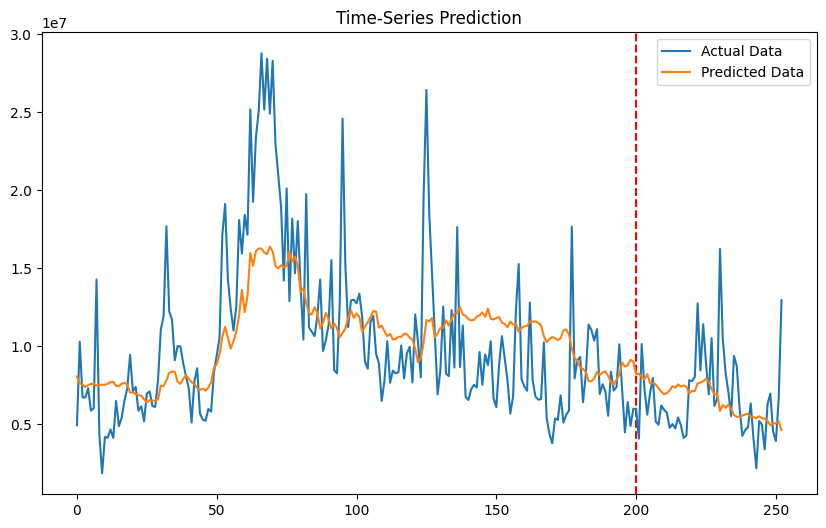

In [ ]:
train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)

plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()